# Olabanjo's Analysis: nonlinear demand–supply–price model

This notebook is a strengthened reproducibility workflow for the manuscript **“Stability Analysis of a Demand–Supply–Price Model and its Empirical Application to the U.S. Crude Oil Market.”**

### Main improvements
1. Separates the **full 8-parameter model** from the empirically preferred **reduced 6-parameter model** with \(a=\zeta=0\).
2. Uses the reduced model for the principal uncertainty analysis, reducing boundary-identification pathologies.
3. Reports Jacobian-based uncertainty **and a moving-block bootstrap with convergence diagnostics**.
4. Retains the 97-month free-running structural extrapolation test, but adds **rolling-origin 1-, 3-, 6-, and 12-month forecasts**.
5. Compares forecasts with a **persistence benchmark** instead of interpreting negative long-horizon \(R^2\) in isolation.
6. Adds **HAC/Newey–West inference** for the empirical price-growth/imbalance diagnostic.
7. Provides annotated global sensitivity heatmaps and reports the valid Monte Carlo sample.
8. Treats numerical continuation as confirmation of the analytical **no-\(\chi\)-Hopf** result, not as a search for a desired bifurcation.
9. Uses \(\Omega=a\eta+\nu(b-\zeta)\) consistently.
10. Exports publication-ready tables, figures, and a machine-readable results summary.

`FAST_MODE=True` is for checking the notebook. Set `FAST_MODE=False` for the final manuscript run.

In [1]:
import os, math, json, warnings, platform, sys
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from numpy.linalg import eigvals, pinv
from scipy.stats import spearmanr

try:
    import statsmodels.api as sm
    HAVE_STATSMODELS = True
except Exception:
    HAVE_STATSMODELS = False

SEED = 20261015
rng = np.random.default_rng(SEED)

FAST_MODE = False

# Publication settings
N_STARTS_FULL = 8 if FAST_MODE else 40
N_STARTS_REDUCED = 8 if FAST_MODE else 40
BOOTSTRAP_TARGET = 50 if FAST_MODE else 1000      # successful replications
BOOTSTRAP_MAX_ATTEMPTS = 100 if FAST_MODE else 1600
MC_SENSITIVITY = 400 if FAST_MODE else 5000
ROLLING_REFIT_STARTS = 2 if FAST_MODE else 2

FIGDIR = Path("figures")
TABDIR = Path("tables")
FIGDIR.mkdir(exist_ok=True)
TABDIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11
})

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("FAST_MODE =", FAST_MODE)

Python: 3.14.6
NumPy: 2.4.6
Pandas: 3.0.3
FAST_MODE = False


## 1. Load and verify the harmonized EIA data

In [2]:
candidates = [
    Path("EIA_LV_Demand_Supply_Harmonized.xlsx"),
    Path("/mnt/data/EIA_LV_Demand_Supply_Harmonized.xlsx")
]
DATA_FILE = next((p for p in candidates if p.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError("Place EIA_LV_Demand_Supply_Harmonized.xlsx beside the notebook.")

df = pd.read_excel(DATA_FILE, sheet_name="LV Ready")
df.columns = ["t", "date", "D_raw", "S_raw", "P_raw", "d", "s", "p"]
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

assert len(df) == 485
assert df[["d","s","p"]].notna().all().all()
assert (df[["d","s","p"]] > 0).all().all()
assert df["date"].is_monotonic_increasing

Y = df[["d","s","p"]].to_numpy(float)
t = df["t"].to_numpy(float)
x0 = Y[0].copy()
STATE_NAMES = ["Demand", "Supply", "Price"]

print(f"Sample: {df.date.min().date()} to {df.date.max().date()} | N={len(df)}")
display(df.head())

Sample: 1986-01-01 to 2026-05-01 | N=485


,t,date,D_raw,S_raw,P_raw,d,s,p
0,0,1986-01-01,498728,283248,22.925455,0.860666,1.179242,0.473092
1,1,1986-02-01,453209,256855,15.454737,0.782113,1.069361,0.318926
2,2,1986-03-01,504565,279413,12.612500,0.870739,1.163276,0.260273
3,3,1986-04-01,478339,265917,12.843636,0.825481,1.107088,0.265043
4,4,1986-05-01,495789,273964,15.377619,0.855594,1.140590,0.317334


,count,mean,std,min,25%,50%,75%,max
D_raw,485.0,579467.288660,45860.339785,436455.000000,542427.000000,585109.000000,616161.000000,671648.000000
S_raw,485.0,240194.917526,79267.920472,119208.000000,176441.000000,214269.000000,282371.000000,429777.000000
P_raw,485.0,48.458743,29.466584,11.347273,20.252500,43.149524,71.533158,133.880000
d,485.0,1.000000,0.079142,0.753200,0.936079,1.009736,1.063323,1.159078
s,485.0,1.000000,0.330015,0.496297,0.734574,0.892063,1.175591,1.789284
p,485.0,1.000000,0.608076,0.234164,0.417933,0.890438,1.476166,2.762763


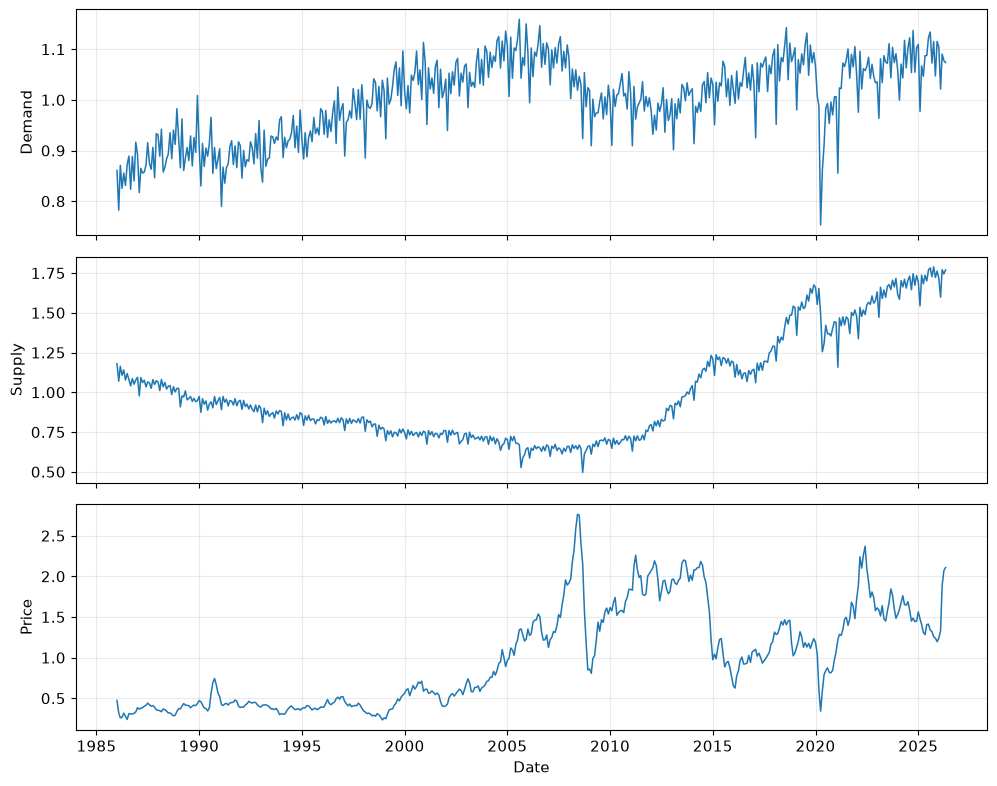

In [3]:
desc = df[["D_raw","S_raw","P_raw","d","s","p"]].describe().T
display(desc)
desc.to_csv(TABDIR/"descriptive_statistics.csv")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for j, col in enumerate(["d","s","p"]):
    axes[j].plot(df["date"], df[col], lw=1.1)
    axes[j].set_ylabel(STATE_NAMES[j])
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"normalized_states.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Model, solver, metrics, and estimation utilities

In [4]:
FULL_NAMES = ["rho","a","nu","mu","b","zeta","eta","chi"]
REDUCED_NAMES = ["rho","nu","mu","b","eta","chi"]

def rhs_autonomous(t, x, theta):
    rho,a,nu,mu,b,zeta,eta,chi = np.asarray(theta, float)
    d,s,p = np.maximum(np.asarray(x,float), 1e-12)
    return np.array([
        d*(rho-a*d-nu*p),
        s*(-mu-b*s+zeta*d+eta*p),
        chi*p*(d-s)/max(d+s,1e-12)
    ])

def simulate(theta, t_eval, x_init):
    t_eval = np.asarray(t_eval,float)
    sol = solve_ivp(
        rhs_autonomous, (float(t_eval[0]),float(t_eval[-1])),
        np.asarray(x_init,float), t_eval=t_eval, args=(np.asarray(theta,float),),
        method="LSODA", rtol=1e-8, atol=1e-10
    )
    if (not sol.success) or sol.y.shape[1] != len(t_eval):
        return None
    out = sol.y.T
    if not np.isfinite(out).all():
        return None
    return out

def metrics(y, yh):
    e = np.asarray(y)-np.asarray(yh)
    den = np.sum((y-np.mean(y))**2)
    return {
        "SSE": float(np.sum(e**2)),
        "RMSE": float(np.sqrt(np.mean(e**2))),
        "MAE": float(np.mean(np.abs(e))),
        "R2": float(1-np.sum(e**2)/den) if den > 0 else np.nan
    }

def state_metrics(Yobs, Yhat):
    return pd.DataFrame(
        [metrics(Yobs[:,j],Yhat[:,j]) for j in range(3)],
        index=STATE_NAMES
    )

def reduced_to_full(theta6):
    rho,nu,mu,b,eta,chi = np.asarray(theta6,float)
    return np.array([rho,0.0,nu,mu,b,0.0,eta,chi])

def full_to_reduced(theta8):
    rho,a,nu,mu,b,zeta,eta,chi = theta8
    return np.array([rho,nu,mu,b,eta,chi])

def residual_log(logtheta, t_eval, Yobs, x_init, reduced=False):
    vals = np.exp(np.clip(logtheta,-35,5))
    theta = reduced_to_full(vals) if reduced else vals
    pred = simulate(theta,t_eval,x_init)
    if pred is None:
        return np.full(Yobs.size,1e6)
    return (pred-Yobs).ravel()

def multistart_fit(start_theta, t_eval, Yobs, x_init, reduced=False,
                   n_starts=10, max_nfev=3000, seed=SEED):
    rrng = np.random.default_rng(seed)
    starts = [np.log(np.asarray(start_theta,float))]
    for _ in range(n_starts-1):
        starts.append(starts[0] + rrng.normal(0,0.75,len(start_theta)))
    fits=[]
    for i,z0 in enumerate(starts,1):
        r = least_squares(
            residual_log,z0,args=(t_eval,Yobs,x_init,reduced),
            method="trf",max_nfev=max_nfev,
            xtol=1e-9,ftol=1e-9,gtol=1e-9
        )
        fits.append(r)
        print(f"{i:02d}/{n_starts}: SSE={2*r.cost:.6f} success={r.success}")
    best=min(fits,key=lambda r:r.cost)
    vals=np.exp(best.x)
    theta= reduced_to_full(vals) if reduced else vals
    pred=simulate(theta,t_eval,x_init)
    return theta,best,pred

def information_criteria(sse,n_scalar,k):
    return (
        n_scalar*np.log(sse/n_scalar)+2*k,
        n_scalar*np.log(sse/n_scalar)+k*np.log(n_scalar)
    )

## 3. Full model and principled model reduction

In [5]:
theta_reference = np.array([
    9.3347e-4,3.2e-9,2.8227e-4,3.7058e-3,
    4.7132e-3,3.607e-9,8.5061e-3,3.3518e-2
])

theta_full, fit_full, Yhat_full = multistart_fit(
    theta_reference,t,Y,x0,reduced=False,n_starts=N_STARTS_FULL,
    max_nfev=1500 if FAST_MODE else 5000
)

full_table=pd.DataFrame({"Parameter":FULL_NAMES,"Estimate":theta_full})
display(full_table)
display(state_metrics(Y,Yhat_full))

01/40: SSE=72.145897 success=True
02/40: SSE=72.145897 success=True
03/40: SSE=367.562029 success=True
04/40: SSE=72.145897 success=True
05/40: SSE=72.145897 success=True
06/40: SSE=72.145898 success=True
07/40: SSE=72.145898 success=True
08/40: SSE=72.145897 success=True
09/40: SSE=72.145897 success=True
10/40: SSE=72.145899 success=True
11/40: SSE=72.145899 success=True
12/40: SSE=72.215053 success=True
13/40: SSE=72.145897 success=True
14/40: SSE=72.145897 success=True
15/40: SSE=73.390261 success=True
16/40: SSE=72.145897 success=True
17/40: SSE=72.145897 success=True
18/40: SSE=72.145897 success=True
19/40: SSE=72.145899 success=True
20/40: SSE=72.145897 success=True
21/40: SSE=72.145897 success=True
22/40: SSE=72.145898 success=True
23/40: SSE=72.145897 success=True
24/40: SSE=72.145897 success=True
25/40: SSE=149.663908 success=True
26/40: SSE=72.145899 success=True
27/40: SSE=72.145898 success=True
28/40: SSE=72.145897 success=True
29/40: SSE=72.145897 success=True
30/40: SSE=7

,Parameter,Estimate
0,rho,9.337269e-04
1,a,1.151028e-13
2,nu,2.826458e-04
3,mu,3.708036e-03
4,b,4.709276e-03
5,zeta,1.507498e-14
6,eta,8.505030e-03
7,chi,3.351519e-02


,SSE,RMSE,MAE,R2
Demand,2.576944,0.072892,0.057380,0.149953
Supply,7.117383,0.121140,0.099828,0.864977
Price,62.451570,0.358840,0.261076,0.651034


In [6]:
# Reduced model a=zeta=0, motivated by the boundary estimates in the full model.
start6 = full_to_reduced(theta_full)
theta_reduced, fit_reduced, Yhat_reduced = multistart_fit(
    start6,t,Y,x0,reduced=True,n_starts=N_STARTS_REDUCED,
    max_nfev=1500 if FAST_MODE else 5000,seed=SEED+1
)

SSE_full=float(np.sum((Y-Yhat_full)**2))
SSE_red=float(np.sum((Y-Yhat_reduced)**2))
AIC_full,BIC_full=information_criteria(SSE_full,Y.size,8)
AIC_red,BIC_red=information_criteria(SSE_red,Y.size,6)

model_selection=pd.DataFrame([
    ["Full",8,SSE_full,AIC_full,BIC_full],
    [r"Reduced ($a=\zeta=0$)",6,SSE_red,AIC_red,BIC_red]
],columns=["Model","k","SSE","AIC","BIC"])
display(model_selection)

pd.DataFrame({"Parameter":FULL_NAMES,"Estimate":theta_reduced}).to_csv(
    TABDIR/"reduced_parameter_estimates_full_vector.csv",index=False)
model_selection.to_csv(TABDIR/"model_selection.csv",index=False)

01/40: SSE=72.145897 success=True
02/40: SSE=72.145899 success=True
03/40: SSE=72.215053 success=True
04/40: SSE=72.145897 success=True
05/40: SSE=72.145897 success=True
06/40: SSE=72.145897 success=True
07/40: SSE=72.215053 success=True
08/40: SSE=72.145898 success=True
09/40: SSE=72.145897 success=True
10/40: SSE=72.145898 success=True
11/40: SSE=72.145898 success=True
12/40: SSE=72.145898 success=True
13/40: SSE=72.145897 success=True
14/40: SSE=72.145898 success=True
15/40: SSE=72.145898 success=True
16/40: SSE=72.145898 success=True
17/40: SSE=72.145897 success=True
18/40: SSE=72.145897 success=True
19/40: SSE=72.145898 success=True
20/40: SSE=72.145898 success=True
21/40: SSE=72.145897 success=True
22/40: SSE=72.145898 success=True
23/40: SSE=72.145898 success=True
24/40: SSE=163.484130 success=True
25/40: SSE=72.145899 success=True
26/40: SSE=72.145898 success=True
27/40: SSE=72.145897 success=True
28/40: SSE=72.145898 success=True
29/40: SSE=72.145897 success=True
30/40: SSE=72

,Model,k,SSE,AIC,BIC
0,Full,8,72.145897,-4354.922952,-4312.660862
1,Reduced ($a=\zeta=0$),6,72.145897,-4358.922952,-4327.226384


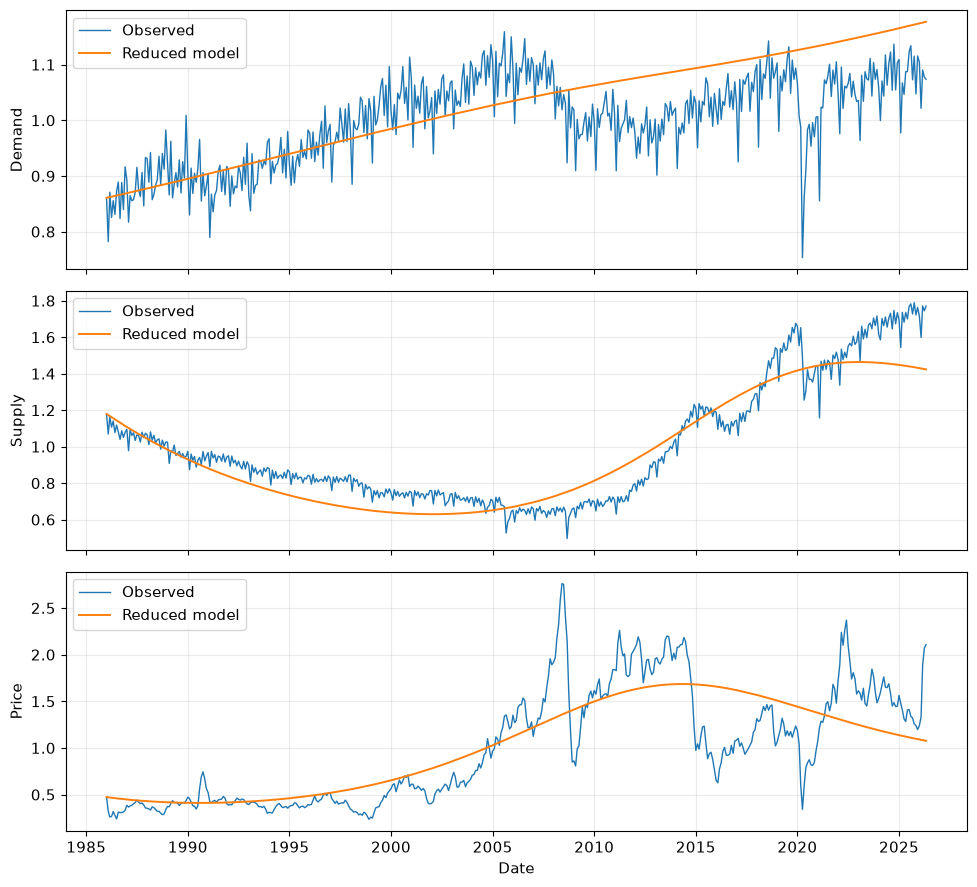

In [7]:
fig, axes = plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,Y[:,j],lw=1.0,label="Observed")
    ax.plot(df.date,Yhat_reduced[:,j],lw=1.4,label="Reduced model")
    ax.set_ylabel(STATE_NAMES[j])
    ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"reduced_observed_fitted_panel.png",dpi=300,bbox_inches="tight")
plt.show()

## 4. Parameter uncertainty for the reduced model

The main inferential table is based on the empirically preferred six-parameter model. This avoids presenting unstable confidence intervals for parameters that collapse to the numerical boundary in the full model.

The moving-block bootstrap targets a specified number of **successful** replications and reports the convergence rate. For publication, run with `FAST_MODE=False`.

In [8]:
# Local covariance in log-parameter space for reduced model
nres=fit_reduced.fun.size
kpar=len(fit_reduced.x)
sigma2=np.sum(fit_reduced.fun**2)/(nres-kpar)
cov_log=sigma2*pinv(fit_reduced.jac.T@fit_reduced.jac)
se_log=np.sqrt(np.maximum(np.diag(cov_log),0))
est6=np.exp(fit_reduced.x)
se6=est6*se_log
z=1.959963984540054
lo6=np.exp(fit_reduced.x-z*se_log)
hi6=np.exp(fit_reduced.x+z*se_log)

local_unc=pd.DataFrame({
    "Parameter":REDUCED_NAMES,"Estimate":est6,
    "SE_delta":se6,"CI95_low":lo6,"CI95_high":hi6
})
display(local_unc)
local_unc.to_csv(TABDIR/"reduced_parameter_uncertainty_local.csv",index=False)

,Parameter,Estimate,SE_delta,CI95_low,CI95_high
0,rho,0.000934,0.000171,0.000653,0.001336
1,nu,0.000283,0.000193,0.000074,0.001077
2,mu,0.003708,0.000404,0.002994,0.004592
3,b,0.004709,0.000342,0.004084,0.005430
4,eta,0.008505,0.000320,0.007900,0.009157
5,chi,0.033515,0.001989,0.029835,0.037649


In [9]:
# Moving-block residual bootstrap for reduced model
resid_red=Y-Yhat_reduced
BLOCK_LEN=12

def moving_block_sample(E,n,L,rng):
    starts=rng.integers(0,len(E)-L+1,size=math.ceil(n/L))
    return np.vstack([E[i:i+L] for i in starts])[:n]

boot=[]
attempts=0
brng=np.random.default_rng(SEED+20)

while len(boot)<BOOTSTRAP_TARGET and attempts<BOOTSTRAP_MAX_ATTEMPTS:
    attempts+=1
    Eb=moving_block_sample(resid_red,len(Y),BLOCK_LEN,brng)
    Yb=np.maximum(Yhat_reduced+Eb,1e-8)

    # Keep the original observed initial state fixed. This avoids letting a
    # resampled residual redefine the conditioning state of every bootstrap fit.
    def rb(z):
        return residual_log(z,t,Yb,x0,reduced=True)

    try:
        rr=least_squares(
            rb,fit_reduced.x,method="trf",
            max_nfev=900 if FAST_MODE else 2500,
            xtol=1e-8,ftol=1e-8,gtol=1e-8
        )
        candidate=np.exp(rr.x)
        if rr.success and np.isfinite(candidate).all() and np.linalg.norm(rr.fun)<1e5:
            boot.append(candidate)
    except Exception:
        pass

    if attempts % max(10,BOOTSTRAP_TARGET//10)==0:
        print(f"attempts={attempts}, successful={len(boot)}")

boot=np.asarray(boot)
success_rate=len(boot)/attempts if attempts else np.nan
print(f"Successful bootstrap fits: {len(boot)}/{attempts} ({success_rate:.1%})")

if len(boot)<max(30,int(.8*BOOTSTRAP_TARGET)):
    print("WARNING: insufficient successful replications for a publication-grade percentile interval.")

boot_tab=pd.DataFrame({
    "Parameter":REDUCED_NAMES,
    "Estimate":est6,
    "Bootstrap_SE":np.std(boot,axis=0,ddof=1),
    "CI2.5":np.quantile(boot,.025,axis=0),
    "Median":np.quantile(boot,.50,axis=0),
    "CI97.5":np.quantile(boot,.975,axis=0)
})
display(boot_tab)
boot_tab.to_csv(TABDIR/"reduced_parameter_block_bootstrap.csv",index=False)
pd.DataFrame(boot,columns=REDUCED_NAMES).to_csv(TABDIR/"bootstrap_draws_reduced.csv",index=False)

attempts=100, successful=100
attempts=200, successful=200
attempts=300, successful=300
attempts=400, successful=400
attempts=500, successful=500
attempts=600, successful=600
attempts=700, successful=700
attempts=800, successful=800
attempts=900, successful=900
attempts=1000, successful=1000
Successful bootstrap fits: 1000/1000 (100.0%)


,Parameter,Estimate,Bootstrap_SE,CI2.5,Median,CI97.5
0,rho,0.000934,0.000159,6.335613e-04,0.000818,0.001191
1,nu,0.000283,0.000185,6.569462e-21,0.000163,0.000591
2,mu,0.003708,0.000954,1.704488e-03,0.003739,0.005422
3,b,0.004709,0.001097,2.448955e-03,0.004217,0.006833
4,eta,0.008505,0.001081,6.506728e-03,0.008255,0.010754
5,chi,0.033515,0.006047,2.732848e-02,0.036460,0.050609


## 5. Equilibrium, eigenvalues, and analytical stability

In [10]:
def equilibrium(theta):
    rho,a,nu,mu,b,zeta,eta,chi=theta
    Omega=a*eta+nu*(b-zeta)
    q=(eta*rho-nu*mu)/Omega
    p=(rho*(b-zeta)+a*mu)/Omega
    return q,p,Omega

def jacobian_eq(theta):
    rho,a,nu,mu,b,zeta,eta,chi=theta
    q,p,Omega=equilibrium(theta)
    return np.array([
        [-a*q,0,-nu*q],
        [zeta*q,-b*q,eta*q],
        [chi*p/(2*q),-chi*p/(2*q),0]
    ])

def stability_summary(theta):
    rho,a,nu,mu,b,zeta,eta,chi=theta
    q,p,Omega=equilibrium(theta)
    lam=eigvals(jacobian_eq(theta))
    c1=(a+b)*q
    c2=a*b*q*q+chi*p*(nu+eta)/2
    c3=chi*p*q*Omega/2
    margin=c1*c2-c3
    margin_closed=a*b*(a+b)*q**3+chi*p*q*(a*nu+b*eta+nu*zeta)/2
    return q,p,Omega,lam,c1,c2,c3,margin,margin_closed

# Theory is evaluated for the fitted full model because strict positivity
# underlies the no-Hopf proposition.
qstar,pstar,Omega,lam,c1,c2,c3,RH,RH_closed=stability_summary(theta_full)
print("q* =",qstar,"p* =",pstar,"Omega =",Omega)
print("Eigenvalues:",lam)
print("c1,c2,c3 =",c1,c2,c3)
print("Routh-Hurwitz margin =",RH)
print("Closed-form margin =",RH_closed)
assert np.isclose(RH,RH_closed,rtol=1e-7,atol=1e-12)

q* = 5.178828575393236 p* = 3.3035234461791707 Omega = 1.3310567697338635e-06
Eigenvalues: [-0.00081675+0.j         -0.01178589+0.01811956j -0.01178589-0.01811956j]
c1,c2,c3 = 0.024388531557634638 0.00048647785627075533 3.8160771181224043e-07
Routh-Hurwitz margin = 1.1482872837937524e-05
Closed-form margin = 1.1482872837937524e-05


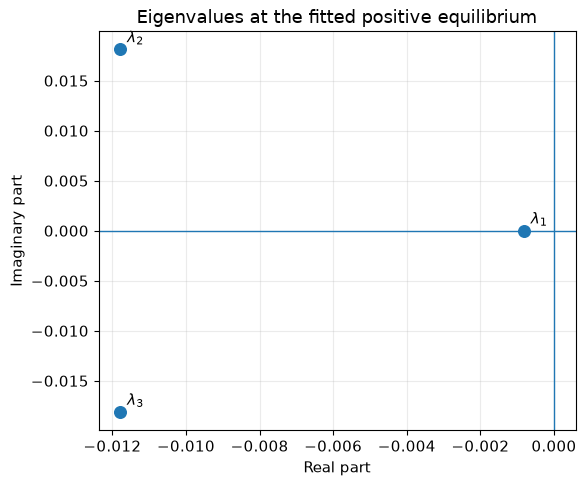

In [11]:
fig,ax=plt.subplots(figsize=(6,5))
ax.scatter(lam.real,lam.imag,s=70)
ax.axvline(0,lw=1)
ax.axhline(0,lw=1)
for i,zv in enumerate(lam,1):
    ax.annotate(fr"$\lambda_{i}$",(zv.real,zv.imag),xytext=(5,5),textcoords="offset points")
ax.set_xlabel("Real part")
ax.set_ylabel("Imaginary part")
ax.set_title("Eigenvalues at the fitted positive equilibrium")
fig.tight_layout()
fig.savefig(FIGDIR/"eigenvalue_complex_plane.png",dpi=300,bbox_inches="tight")
plt.show()

## 6. Numerical continuation in price-adjustment speed

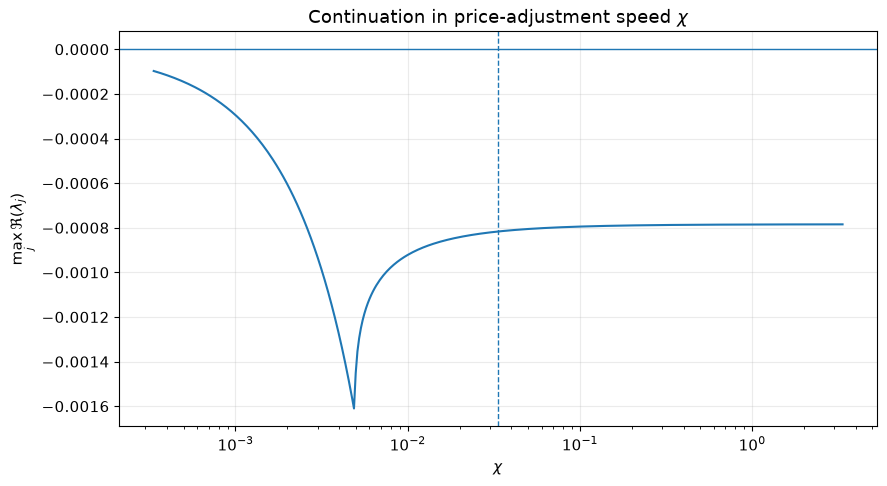

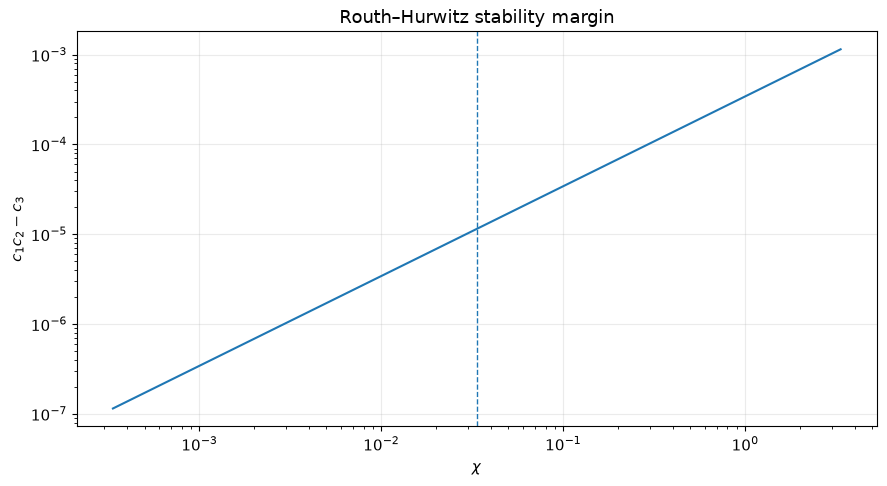

Minimum margin: 1.1482872873038878e-07
Any nonnegative spectral abscissa? False


In [12]:
chi0=theta_full[7]
chi_grid=np.geomspace(max(chi0/100,1e-6),chi0*100,400)
max_real=[]
rh_margin=[]

for ch in chi_grid:
    th=theta_full.copy(); th[7]=ch
    *_,ev,cc1,cc2,cc3,margin,closed=stability_summary(th)
    max_real.append(np.max(np.real(ev)))
    rh_margin.append(margin)

max_real=np.asarray(max_real)
rh_margin=np.asarray(rh_margin)

fig,ax=plt.subplots()
ax.semilogx(chi_grid,max_real,lw=1.5)
ax.axhline(0,lw=1)
ax.axvline(chi0,ls="--",lw=1)
ax.set_xlabel(r"$\chi$")
ax.set_ylabel(r"$\max_j \Re(\lambda_j)$")
ax.set_title(r"Continuation in price-adjustment speed $\chi$")
fig.tight_layout()
fig.savefig(FIGDIR/"continuation_chi_spectral_abscissa.png",dpi=300,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots()
ax.loglog(chi_grid,rh_margin,lw=1.5)
ax.axvline(chi0,ls="--",lw=1)
ax.set_xlabel(r"$\chi$")
ax.set_ylabel(r"$c_1c_2-c_3$")
ax.set_title("Routh–Hurwitz stability margin")
fig.tight_layout()
fig.savefig(FIGDIR/"rh_margin_chi.png",dpi=300,bbox_inches="tight")
plt.show()

print("Minimum margin:",rh_margin.min())
print("Any nonnegative spectral abscissa?",bool(np.any(max_real>=0)))

## 7. Local and global sensitivity analysis

In [13]:
def diagnostics(theta):
    try:
        q,p,Om=equilibrium(theta)
        if not np.isfinite([q,p,Om]).all() or q<=0 or p<=0:
            return [np.nan]*4
        sa=float(np.max(eigvals(jacobian_eq(theta)).real))
        pr=simulate(theta,t,x0)
        if pr is None:
            return [np.nan]*4
        sse=float(np.sum((pr-Y)**2))
        return q,p,sa,sse
    except Exception:
        return [np.nan]*4

base=np.asarray(diagnostics(theta_full))
rows=[]
for j,pname in enumerate(FULL_NAMES):
    for frac in (-.10,.10):
        th=theta_full.copy(); th[j]*=(1+frac)
        vals=np.asarray(diagnostics(th))
        rel=(vals-base)/np.where(np.abs(base)>1e-14,np.abs(base),1)
        rows.append([pname,frac,*vals,*rel])

local_sens=pd.DataFrame(rows,columns=[
    "Parameter","Perturbation","q_star","p_star","spectral_abscissa","SSE",
    "rel_q","rel_p","rel_spectral","rel_SSE"
])
display(local_sens)
local_sens.to_csv(TABDIR/"local_sensitivity_pm10.csv",index=False)

,Parameter,Perturbation,q_star,p_star,spectral_abscissa,SSE,rel_q,rel_p,rel_spectral,rel_SSE
0,rho,-0.1,4.582207,2.973171,-0.000719,73.275704,-1.152040e-01,-1.000000e-01,1.200911e-01,1.566003e-02
1,rho,0.1,5.775450,3.633876,-0.000916,73.327913,1.152040e-01,1.000000e-01,-1.215262e-01,1.638368e-02
2,a,-0.1,5.178829,3.303523,-0.000817,72.145897,7.354700e-11,6.384045e-11,-3.659793e-12,-1.634883e-14
3,a,0.1,5.178829,3.303523,-0.000817,72.145897,-7.354717e-11,-6.384085e-11,3.656872e-12,1.615186e-14
4,nu,-0.1,5.841742,3.670582,-0.000833,72.224304,1.280045e-01,1.111111e-01,-2.026920e-02,1.086780e-03
5,nu,0.1,4.636445,3.003203,-0.000800,72.221818,-1.047309e-01,-9.090909e-02,2.002387e-02,1.052318e-03
6,mu,-0.1,5.257568,3.303523,-0.000830,74.197822,1.520402e-02,-9.706443e-12,-1.654234e-02,2.844132e-02
7,mu,0.1,5.100090,3.303523,-0.000803,74.217497,-1.520402e-02,9.706308e-12,1.647599e-02,2.871403e-02
8,b,-0.1,5.754254,3.303523,-0.000817,74.115397,1.111111e-01,-7.093426e-11,4.048206e-12,2.729884e-02
9,b,0.1,4.708026,3.303523,-0.000817,73.991989,-9.090909e-02,5.803688e-11,-3.312663e-12,2.558831e-02


Valid Monte Carlo draws: 5000/5000 (100.0%)


,q_star,p_star,spectral_abscissa,SSE
rho,0.514209,0.706328,-0.962551,0.027416
a,0.012997,0.012757,-0.016534,-0.005172
nu,-0.516660,-0.711570,0.180693,-0.000551
mu,-0.080981,-0.022040,0.144128,0.101405
b,-0.424650,0.009480,-0.009475,0.074861
zeta,0.002999,0.002915,-0.000401,0.005073
eta,0.523860,0.016419,-0.177536,-0.179531
chi,0.005229,0.008415,0.020054,0.011984


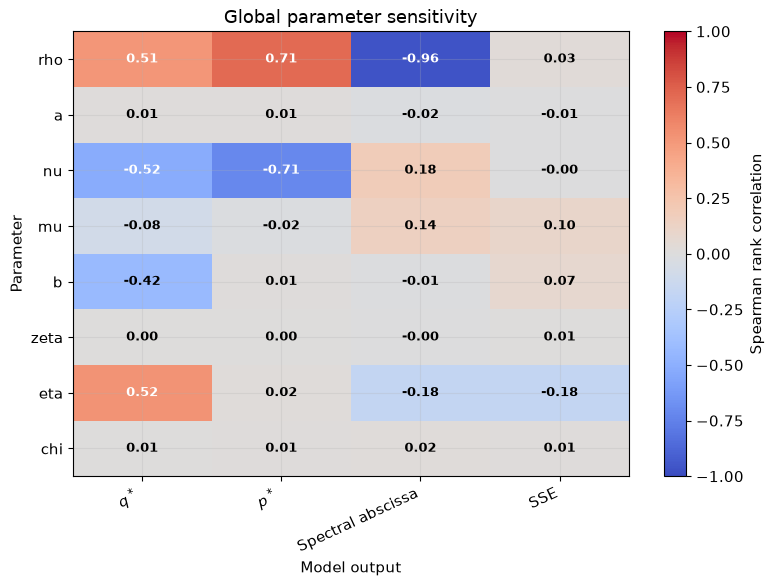

In [14]:
# Global Monte Carlo screen around fitted full parameter vector.
# Each multiplier lies between 1/1.3 and 1.3 on the log scale.
M=MC_SENSITIVITY
srng=np.random.default_rng(SEED+30)
Z=srng.uniform(-1,1,size=(M,8))
Theta_mc=theta_full[None,:]*np.exp(Z*np.log(1.3))

records=[]
for th in Theta_mc:
    records.append([*th,*diagnostics(th)])

mc=pd.DataFrame(records,columns=FULL_NAMES+["q_star","p_star","spectral_abscissa","SSE"])
mc=mc.replace([np.inf,-np.inf],np.nan).dropna()
print(f"Valid Monte Carlo draws: {len(mc)}/{M} ({len(mc)/M:.1%})")

rankcorr=mc.corr(method="spearman").loc[
    FULL_NAMES,["q_star","p_star","spectral_abscissa","SSE"]
]
display(rankcorr)

fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(rankcorr.values,aspect="auto",vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(np.arange(4))
ax.set_xticklabels([r"$q^*$",r"$p^*$","Spectral abscissa","SSE"],rotation=25,ha="right")
ax.set_yticks(np.arange(8))
ax.set_yticklabels(FULL_NAMES)

for i in range(rankcorr.shape[0]):
    for j in range(rankcorr.shape[1]):
        value=rankcorr.iloc[i,j]
        ax.text(j,i,f"{value:.2f}",ha="center",va="center",
                color="white" if abs(value)>=.50 else "black",
                fontsize=9,fontweight="bold")

cbar=fig.colorbar(im,ax=ax)
cbar.set_label("Spearman rank correlation")
ax.set_title("Global parameter sensitivity")
ax.set_xlabel("Model output")
ax.set_ylabel("Parameter")
fig.tight_layout()
fig.savefig(FIGDIR/"global_sensitivity_heatmap.png",dpi=300,bbox_inches="tight")
plt.show()

rankcorr.to_csv(TABDIR/"global_sensitivity_rank_correlations.csv")

## 8. Chronological structural extrapolation

This retains the demanding 80/20 experiment: fit once on the first 388 months and propagate freely through the final 97 months. It should be described as **long-horizon structural extrapolation**, not as a conventional one-step forecasting exercise.

01/20: SSE=29.324743 success=True
02/20: SSE=29.372318 success=True
03/20: SSE=31.103547 success=True
04/20: SSE=29.324742 success=True
05/20: SSE=29.324741 success=True
06/20: SSE=29.324742 success=True
07/20: SSE=29.324741 success=True
08/20: SSE=29.369839 success=True
09/20: SSE=29.324742 success=True
10/20: SSE=29.324743 success=True
11/20: SSE=29.324750 success=True
12/20: SSE=29.324748 success=True
13/20: SSE=29.324744 success=True
14/20: SSE=32.575338 success=True
15/20: SSE=29.324745 success=True
16/20: SSE=29.376000 success=True
17/20: SSE=29.324741 success=True
18/20: SSE=29.324741 success=True
19/20: SSE=29.324744 success=True
20/20: SSE=29.324741 success=True


SSE      RMSE       MAE        R2
Sample      State                                          
Calibration Demand   2.326930  0.077442  0.058721 -0.013224
            Supply   3.193489  0.090723  0.070143  0.732922
            Price   23.804322  0.247692  0.172167  0.835271
Validation  Demand   3.205332  0.181782  0.174780 -7.678313
            Supply  14.961824  0.392741  0.349268 -7.402567
            Price   92.454963  0.976291  0.866810 -6.213916

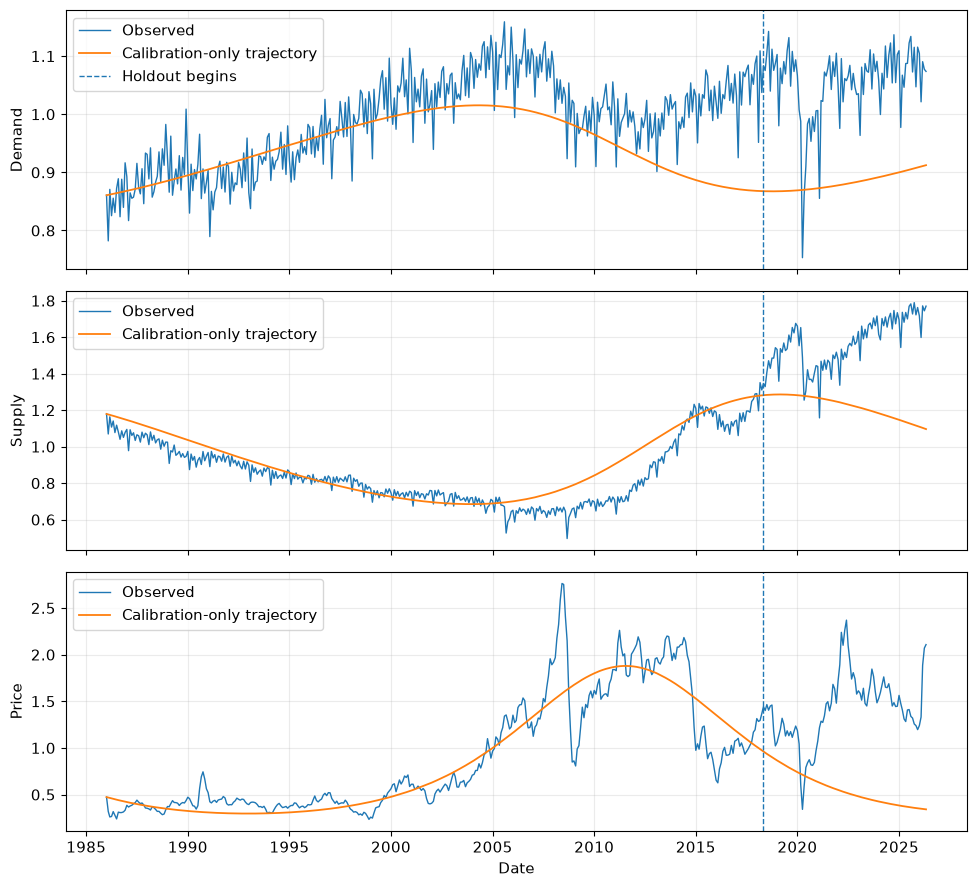

In [15]:
n_train=int(np.floor(.80*len(df)))
t_tr,Y_tr=t[:n_train],Y[:n_train]
t_va,Y_va=t[n_train:],Y[n_train:]

theta_train,fit_train,pred_tr_fit=multistart_fit(
    full_to_reduced(theta_reduced),t_tr,Y_tr,Y_tr[0],reduced=True,
    n_starts=4 if FAST_MODE else 20,max_nfev=1500 if FAST_MODE else 4000,
    seed=SEED+40
)

pred_all=simulate(theta_train,t,Y[0])
pred_tr=pred_all[:n_train]
pred_va=pred_all[n_train:]

long_validation=pd.concat({
    "Calibration":state_metrics(Y_tr,pred_tr),
    "Validation":state_metrics(Y_va,pred_va)
},names=["Sample","State"])
display(long_validation)
long_validation.to_csv(TABDIR/"long_horizon_structural_validation.csv")

fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,Y[:,j],lw=1,label="Observed")
    ax.plot(df.date,pred_all[:,j],lw=1.3,label="Calibration-only trajectory")
    ax.axvline(df.date.iloc[n_train],ls="--",lw=1,label="Holdout begins" if j==0 else None)
    ax.set_ylabel(STATE_NAMES[j])
    ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"out_of_sample_propagation.png",dpi=300,bbox_inches="tight")
plt.show()

## 9. Rolling-origin short-horizon forecasting with persistence benchmark

This is the key empirical strengthening. For each forecast origin in the final 97 months, the reduced model is refitted using information available up to that origin and forecasts are produced for \(h=1,3,6,12\) months. Forecast RMSE and MAE are compared with a persistence benchmark that carries the last observed state forward.

Because monthly ODE states are observed on an integer grid, each forecast simulation begins at the observed state at the forecast origin.

In [16]:
HORIZONS = [1, 3, 6, 12]

origins = range(
    n_train - 1,
    len(df) - max(HORIZONS)
)

forecast_rows = []
failed_origins = []

# Start from calibration estimate
prev_start = full_to_reduced(theta_train).copy()


def valid_theta6(theta):
    """Check whether a reduced-model parameter vector is numerically usable."""
    theta = np.asarray(theta, dtype=float)

    return (
        theta.shape == (6,)
        and np.all(np.isfinite(theta))
        and np.all(theta > 0)
        and np.all(theta < 10.0)
    )


def safe_forecast(theta8, x_origin, horizon):
    """
    Forecast from an observed state.
    Returns None if integration fails or produces non-finite values.
    """
    try:
        theta8 = np.asarray(theta8, dtype=float)
        x_origin = np.asarray(x_origin, dtype=float)

        if not np.all(np.isfinite(theta8)):
            return None

        if not np.all(np.isfinite(x_origin)):
            return None

        if np.any(x_origin <= 0):
            return None

        grid = np.arange(
            0,
            horizon + 1,
            dtype=float
        )

        pred = simulate(
            theta8,
            grid,
            x_origin
        )

        if pred is None:
            return None

        if pred.shape != (len(grid), 3):
            return None

        if not np.all(np.isfinite(pred)):
            return None

        # Reject obviously exploded trajectories
        if np.max(np.abs(pred)) > 1e6:
            return None

        return pred

    except Exception:
        return None


for count, origin in enumerate(origins, 1):

    t_est = t[:origin + 1]
    Y_est = Y[:origin + 1]

    # ---------------------------------------------------
    # Basic data checks
    # ---------------------------------------------------

    if (
        not np.all(np.isfinite(t_est))
        or not np.all(np.isfinite(Y_est))
        or np.any(Y_est <= 0)
    ):
        print(
            f"Skipping origin {origin}: "
            "non-finite/non-positive estimation data."
        )

        failed_origins.append(
            [origin, df.date.iloc[origin], "invalid estimation data"]
        )

        continue

    # ---------------------------------------------------
    # Rolling refit
    # ---------------------------------------------------

    try:

        theta_o, fit_o, _ = multistart_fit(
            prev_start,
            t_est,
            Y_est,
            Y_est[0],
            reduced=True,
            n_starts=ROLLING_REFIT_STARTS,
            max_nfev=700 if FAST_MODE else 700,
            seed=SEED + 1000 + origin
        )

        theta6_o = full_to_reduced(theta_o)

        if not valid_theta6(theta6_o):
            raise ValueError(
                "Rolling fit produced invalid parameters."
            )

        # Update warm start ONLY after successful fit
        prev_start = theta6_o.copy()

    except Exception as exc:

        print(
            f"Origin {origin} "
            f"({df.date.iloc[origin].date()}): "
            f"refit failed -> using previous valid estimate."
        )

        failed_origins.append(
            [
                origin,
                df.date.iloc[origin],
                f"refit failure: {str(exc)}"
            ]
        )

        # Use last valid estimate
        theta_o = reduced_to_full(prev_start)

    # ---------------------------------------------------
    # Forecast
    # ---------------------------------------------------

    pred_path = safe_forecast(
        theta_o,
        Y[origin],
        max(HORIZONS)
    )

    # If the newly estimated model explodes,
    # retry with previous valid parameter vector
    if pred_path is None:

        theta_fallback = reduced_to_full(prev_start)

        pred_path = safe_forecast(
            theta_fallback,
            Y[origin],
            max(HORIZONS)
        )

    if pred_path is None:

        print(
            f"Origin {origin}: forecast integration failed."
        )

        failed_origins.append(
            [
                origin,
                df.date.iloc[origin],
                "forecast integration failure"
            ]
        )

        continue

    # ---------------------------------------------------
    # Store forecasts
    # ---------------------------------------------------

    for h in HORIZONS:

        target = Y[origin + h]
        model_fc = pred_path[h]
        persist_fc = Y[origin]

        if (
            not np.all(np.isfinite(target))
            or not np.all(np.isfinite(model_fc))
            or not np.all(np.isfinite(persist_fc))
        ):
            continue

        for j, state in enumerate(STATE_NAMES):

            forecast_rows.append([
                df.date.iloc[origin],
                h,
                state,
                target[j],
                model_fc[j],
                persist_fc[j],
                model_fc[j] - target[j],
                persist_fc[j] - target[j]
            ])

    if count % 10 == 0:
        print(
            f"Completed {count} forecast origins "
            f"| stored rows = {len(forecast_rows)} "
            f"| failures = {len(failed_origins)}"
        )


# =======================================================
# BUILD FORECAST DATAFRAME
# =======================================================

fc = pd.DataFrame(
    forecast_rows,
    columns=[
        "Origin",
        "Horizon",
        "State",
        "Actual",
        "ModelForecast",
        "PersistenceForecast",
        "ModelError",
        "PersistenceError"
    ]
)


# Final numerical safety check
fc = fc.replace(
    [np.inf, -np.inf],
    np.nan
)

before = len(fc)

fc = fc.dropna(
    subset=[
        "Actual",
        "ModelForecast",
        "PersistenceForecast",
        "ModelError",
        "PersistenceError"
    ]
)

print(
    f"\nRemoved {before - len(fc)} "
    "non-finite forecast rows."
)


# =======================================================
# SUMMARY FUNCTION
# =======================================================

def forecast_summary(g):

    model_error = np.asarray(
        g["ModelError"],
        dtype=float
    )

    persistence_error = np.asarray(
        g["PersistenceError"],
        dtype=float
    )

    good = (
        np.isfinite(model_error)
        & np.isfinite(persistence_error)
    )

    model_error = model_error[good]
    persistence_error = persistence_error[good]

    if len(model_error) == 0:

        return pd.Series({
            "Model_RMSE": np.nan,
            "Persistence_RMSE": np.nan,
            "RMSE_ratio": np.nan,
            "Model_MAE": np.nan,
            "Persistence_MAE": np.nan,
            "MAE_ratio": np.nan,
            "N_forecasts": 0
        })

    rmse_m = np.sqrt(
        np.mean(model_error ** 2)
    )

    rmse_p = np.sqrt(
        np.mean(persistence_error ** 2)
    )

    mae_m = np.mean(
        np.abs(model_error)
    )

    mae_p = np.mean(
        np.abs(persistence_error)
    )

    return pd.Series({

        "Model_RMSE":
            rmse_m,

        "Persistence_RMSE":
            rmse_p,

        "RMSE_ratio":
            rmse_m / rmse_p
            if rmse_p > 0 else np.nan,

        "Model_MAE":
            mae_m,

        "Persistence_MAE":
            mae_p,

        "MAE_ratio":
            mae_m / mae_p
            if mae_p > 0 else np.nan,

        "N_forecasts":
            len(model_error)

    })


# =======================================================
# COMPUTE SUMMARY
# =======================================================

if len(fc) == 0:

    raise RuntimeError(
        "No valid rolling-origin forecasts were generated."
    )


fc_summary = (
    fc
    .groupby(
        ["Horizon", "State"],
        observed=True
    )
    .apply(
        forecast_summary,
        include_groups=False
    )
    .reset_index()
)


display(fc_summary)


# =======================================================
# FAILURE DIAGNOSTICS
# =======================================================

failed_df = pd.DataFrame(
    failed_origins,
    columns=[
        "OriginIndex",
        "OriginDate",
        "Reason"
    ]
)

print(
    "\nValid forecast rows:",
    len(fc)
)

print(
    "Problematic origins:",
    len(failed_df)
)

if len(failed_df) > 0:
    display(failed_df)


# =======================================================
# EXPORT
# =======================================================

fc.to_csv(
    TABDIR / "rolling_origin_forecasts.csv",
    index=False
)

fc_summary.to_csv(
    TABDIR / "rolling_origin_forecast_summary.csv",
    index=False
)

failed_df.to_csv(
    TABDIR / "rolling_origin_failures.csv",
    index=False
)

01/2: SSE=29.324741 success=True
02/2: SSE=29.324741 success=True
01/2: SSE=29.603837 success=True
02/2: SSE=29.603996 success=True
01/2: SSE=29.840373 success=True
02/2: SSE=29.840372 success=True
01/2: SSE=30.164706 success=True
02/2: SSE=30.164706 success=True
01/2: SSE=30.467245 success=True
02/2: SSE=30.467245 success=True
01/2: SSE=30.756640 success=True
02/2: SSE=30.756640 success=True
01/2: SSE=31.101244 success=True
02/2: SSE=31.101244 success=True
01/2: SSE=31.218777 success=True
02/2: SSE=31.218777 success=True
01/2: SSE=31.312829 success=True
02/2: SSE=31.312829 success=True
Origin 395 (2018-12-01): refit failed -> using previous valid estimate.
01/2: SSE=31.415737 success=True
02/2: SSE=31.415737 success=True
Origin 396 (2019-01-01): refit failed -> using previous valid estimate.
Completed 10 forecast origins | stored rows = 120 | failures = 2
01/2: SSE=31.470749 success=True
02/2: SSE=247.003449 success=True
Origin 397 (2019-02-01): refit failed -> using previous valid es

,Horizon,State,Model_RMSE,Persistence_RMSE,RMSE_ratio,Model_MAE,Persistence_MAE,MAE_ratio,N_forecasts
0,1,Demand,0.063650,0.063634,1.000265,0.048916,0.048915,1.000022,86.0
1,1,Price,0.129683,0.129712,0.999779,0.104059,0.103683,1.003621,86.0
2,1,Supply,0.092256,0.092782,0.994337,0.069798,0.070012,0.996946,86.0
3,3,Demand,0.073544,0.073626,0.998880,0.053062,0.053074,0.999783,86.0
4,3,Price,0.247090,0.247990,0.996369,0.181725,0.180953,1.004270,86.0
5,3,Supply,0.098911,0.101161,0.977761,0.071034,0.073787,0.962684,86.0
6,6,Demand,0.089904,0.090262,0.996041,0.064502,0.064954,0.993045,86.0
7,6,Price,0.321744,0.322799,0.996732,0.245640,0.252000,0.974762,86.0
8,6,Supply,0.124172,0.128686,0.964920,0.094345,0.100541,0.938367,86.0
9,12,Demand,0.077062,0.078639,0.979944,0.048231,0.049526,0.973855,86.0



Valid forecast rows: 1032
Problematic origins: 5


,OriginIndex,OriginDate,Reason
0,395,2018-12-01,refit failure: Rolling fit produced invalid pa...
1,396,2019-01-01,refit failure: Rolling fit produced invalid pa...
2,397,2019-02-01,refit failure: Rolling fit produced invalid pa...
3,398,2019-03-01,refit failure: Rolling fit produced invalid pa...
4,401,2019-06-01,refit failure: Rolling fit produced invalid pa...


Horizon,1,3,6,12
State,,,,
Demand,1.000265,0.998880,0.996041,0.979944
Price,0.999779,0.996369,0.996732,1.026436
Supply,0.994337,0.977761,0.964920,0.923553


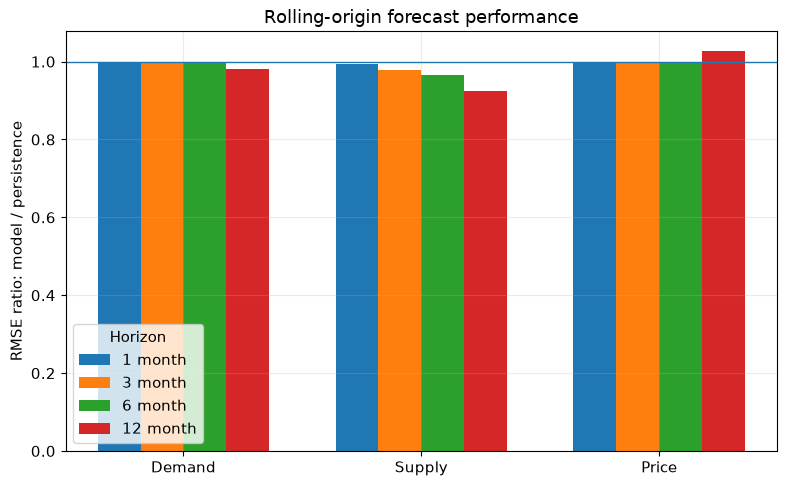

In [17]:
# Plot RMSE ratios: values < 1 favor the nonlinear model over persistence.
pivot=fc_summary.pivot(index="State",columns="Horizon",values="RMSE_ratio")
display(pivot)

fig,ax=plt.subplots(figsize=(8,5))
x=np.arange(len(STATE_NAMES))
width=.18
for k,h in enumerate(HORIZONS):
    ax.bar(x+(k-1.5)*width,pivot[h].reindex(STATE_NAMES).values,width,label=f"{h} month")
ax.axhline(1,lw=1)
ax.set_xticks(x)
ax.set_xticklabels(STATE_NAMES)
ax.set_ylabel("RMSE ratio: model / persistence")
ax.set_title("Rolling-origin forecast performance")
ax.legend(title="Horizon")
fig.tight_layout()
fig.savefig(FIGDIR/"rolling_origin_rmse_ratios.png",dpi=300,bbox_inches="tight")
plt.show()

## 10. Price-growth and imbalance diagnostic with HAC inference

HAC slope=0.026254, SE=0.033961, p=0.4399, 95% CI=(-0.040475,0.092983)


,Slope,SE,CI_low,CI_high,p_value,Inference
0,0.026254,0.033961,-0.040475,0.092983,0.43986,HAC(12)


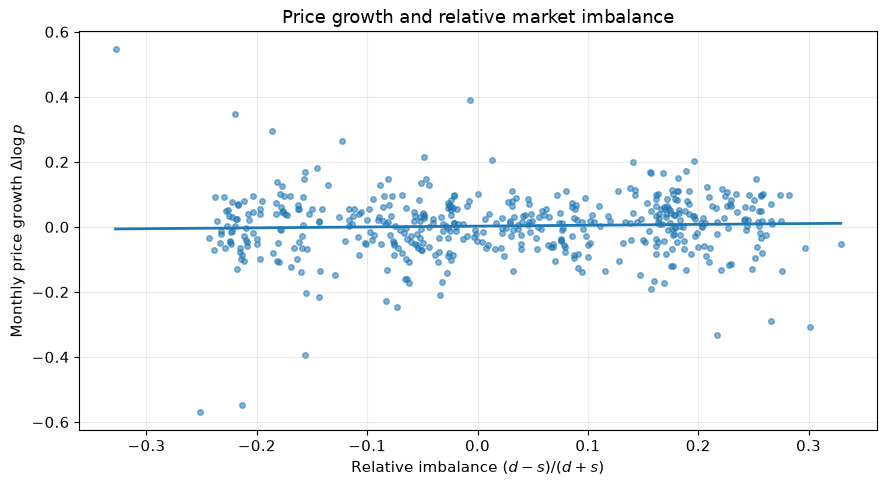

In [18]:
imb=((df.d-df.s)/(df.d+df.s)).to_numpy()
dlogp=np.diff(np.log(df.p.to_numpy()))
X=imb[:-1]

if HAVE_STATSMODELS:
    Xmat=sm.add_constant(X)
    ols=sm.OLS(dlogp,Xmat).fit()
    hac=ols.get_robustcov_results(cov_type="HAC",maxlags=12)
    slope=float(hac.params[1])
    se=float(hac.bse[1])
    pval=float(hac.pvalues[1])
    ci=hac.conf_int(alpha=.05)[1]
    print(f"HAC slope={slope:.6f}, SE={se:.6f}, p={pval:.4f}, 95% CI=({ci[0]:.6f},{ci[1]:.6f})")
else:
    slope=np.sum((X-X.mean())*(dlogp-dlogp.mean()))/np.sum((X-X.mean())**2)
    intercept=dlogp.mean()-slope*X.mean()
    e=dlogp-(intercept+slope*X)
    s2=np.sum(e**2)/(len(X)-2)
    se=np.sqrt(s2/np.sum((X-X.mean())**2))
    pval=np.nan
    ci=(slope-1.96*se,slope+1.96*se)
    print("statsmodels unavailable; conventional OLS inference shown instead.")

diag=pd.DataFrame([{
    "Slope":slope,"SE":se,"CI_low":ci[0],"CI_high":ci[1],"p_value":pval,
    "Inference":"HAC(12)" if HAVE_STATSMODELS else "Conventional OLS"
}])
display(diag)
diag.to_csv(TABDIR/"price_growth_imbalance_regression.csv",index=False)

intercept=(dlogp-slope*X).mean()
fig,ax=plt.subplots()
ax.scatter(X,dlogp,s=16,alpha=.55)
xx=np.linspace(X.min(),X.max(),200)
ax.plot(xx,intercept+slope*xx,lw=2)
ax.set_xlabel(r"Relative imbalance $(d-s)/(d+s)$")
ax.set_ylabel(r"Monthly price growth $\Delta\log p$")
ax.set_title("Price growth and relative market imbalance")
fig.tight_layout()
fig.savefig(FIGDIR/"price_growth_imbalance.png",dpi=300,bbox_inches="tight")
plt.show()

## 11. Residual diagnostics

Residual dependence is reported as a model limitation rather than hidden behind independent-error standard errors.

,Demand,Supply,Price
count,485.000000,485.000000,485.000000
mean,-0.026209,0.034114,-0.015641
std,0.068088,0.116358,0.358869
min,-0.374559,-0.287808,-1.084413
25%,-0.070350,-0.056327,-0.201801
50%,-0.026755,0.043658,-0.045494
75%,0.021471,0.111944,0.164809
max,0.127582,0.354011,1.404842


,State,ACF_lag1,ACF_lag12,Mean,SD
0,Demand,0.653994,0.789879,-0.026209,0.068088
1,Supply,0.877643,0.774694,0.034114,0.116358
2,Price,0.961104,0.436331,-0.015641,0.358869


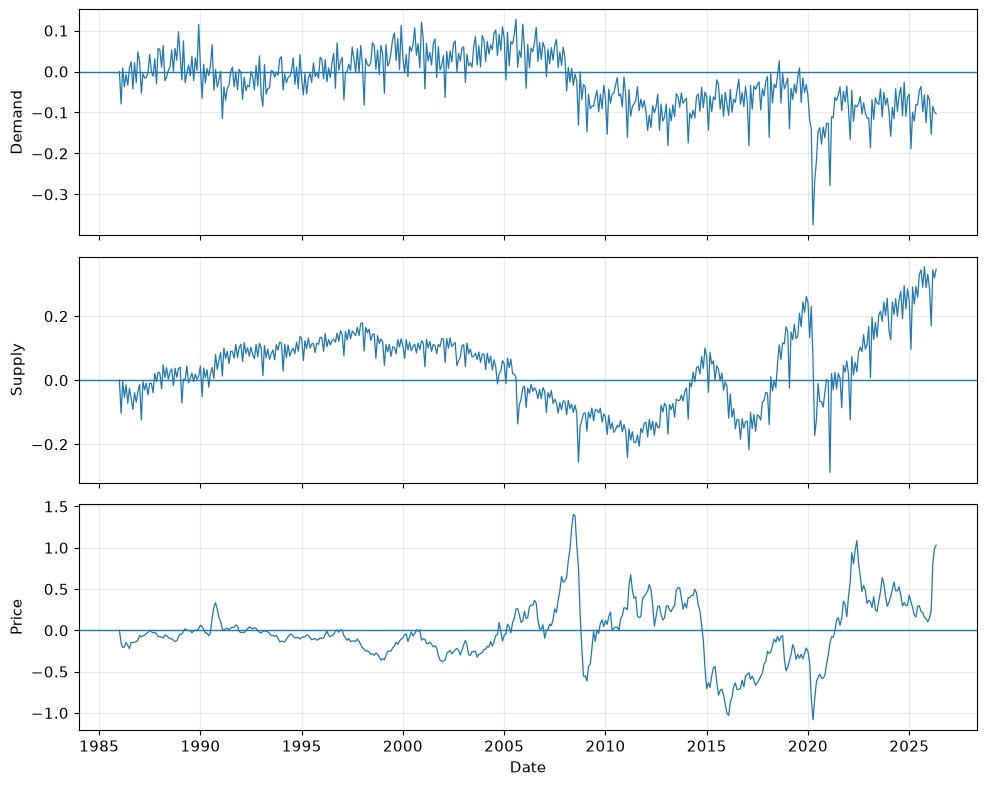

In [19]:
resid=Y-Yhat_reduced
resid_df=pd.DataFrame(resid,columns=STATE_NAMES)
display(resid_df.describe())

diag_rows=[]
for j,name in enumerate(STATE_NAMES):
    r=resid[:,j]
    ac1=np.corrcoef(r[:-1],r[1:])[0,1]
    ac12=np.corrcoef(r[:-12],r[12:])[0,1]
    diag_rows.append([name,ac1,ac12,np.mean(r),np.std(r,ddof=1)])

resid_diag=pd.DataFrame(diag_rows,columns=["State","ACF_lag1","ACF_lag12","Mean","SD"])
display(resid_diag)
resid_diag.to_csv(TABDIR/"residual_diagnostics.csv",index=False)

fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,resid[:,j],lw=.9)
    ax.axhline(0,lw=1)
    ax.set_ylabel(STATE_NAMES[j])
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"residual_time_series.png",dpi=300,bbox_inches="tight")
plt.show()

## 12. Optional stochastic robustness experiment

This section is deliberately **secondary**. It does not create a fitted stochastic model and must not be reported as a calibrated prediction interval. Its sole purpose is to illustrate how random multiplicative disturbances can disperse trajectories around a stable deterministic system.

For a stronger future paper, replace this experiment with a formally estimated stochastic state-space or SDE model.

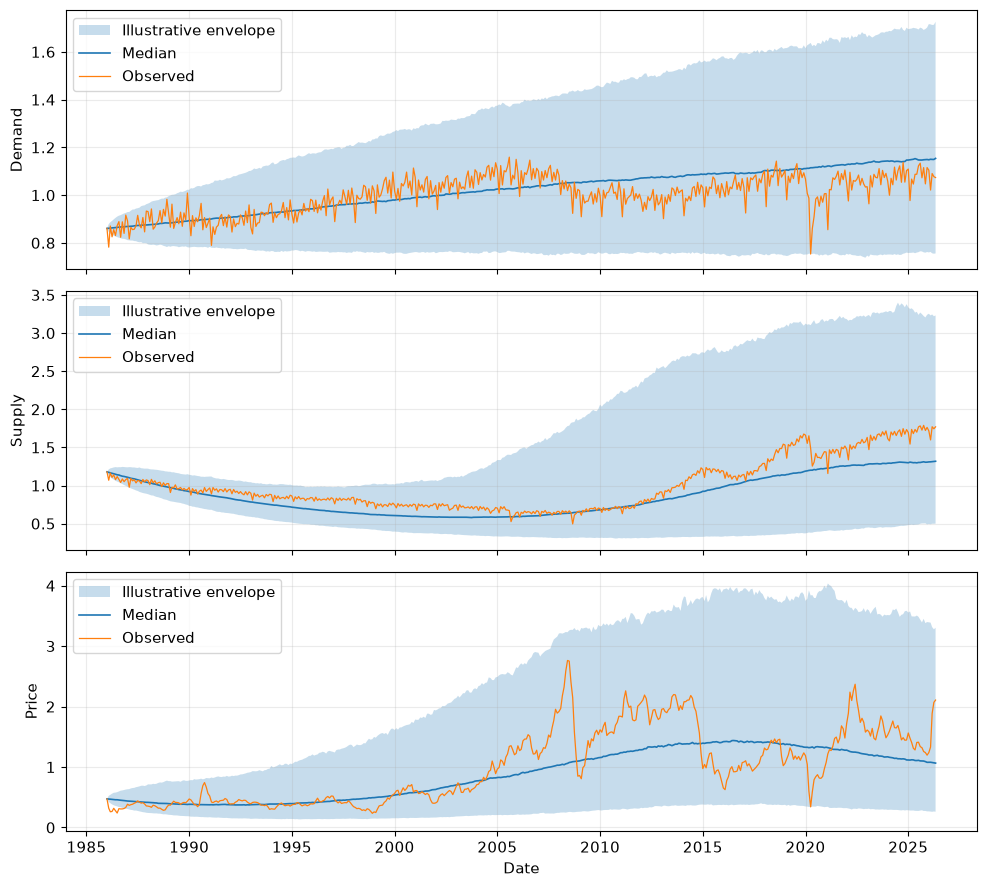

In [20]:
RUN_STOCHASTIC_ILLUSTRATION = True

if RUN_STOCHASTIC_ILLUSTRATION:
    STOCHASTIC_REPS=200 if FAST_MODE else 2000
    sigma=np.std(resid,axis=0,ddof=1)*0.15
    dt=.25
    grid=np.arange(0,t[-1]+dt,dt)
    idx=np.searchsorted(grid,t)
    paths=np.empty((STOCHASTIC_REPS,len(t),3))
    srng=np.random.default_rng(SEED+50)

    def em(theta,xinit,sigma,grid,rng):
        X=np.empty((len(grid),3)); X[0]=xinit
        for k in range(1,len(grid)):
            drift=rhs_autonomous(grid[k-1],X[k-1],theta)
            shock=sigma*np.maximum(X[k-1],1e-8)*np.sqrt(dt)*rng.normal(size=3)
            X[k]=np.maximum(X[k-1]+drift*dt+shock,1e-8)
        return X

    for r in range(STOCHASTIC_REPS):
        paths[r]=em(theta_reduced,x0,sigma,grid,srng)[idx]

    lo,med,hi=np.quantile(paths,[.025,.5,.975],axis=0)
    fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
    for j,ax in enumerate(axes):
        ax.fill_between(df.date,lo[:,j],hi[:,j],alpha=.25,label="Illustrative envelope")
        ax.plot(df.date,med[:,j],lw=1.2,label="Median")
        ax.plot(df.date,Y[:,j],lw=.9,label="Observed")
        ax.set_ylabel(STATE_NAMES[j]); ax.legend()
    axes[-1].set_xlabel("Date")
    fig.tight_layout()
    fig.savefig(FIGDIR/"stochastic_robustness_optional.png",dpi=300,bbox_inches="tight")
    plt.show()
else:
    print("Optional stochastic illustration skipped.")

## 13. Publication summary and reproducibility record

In [21]:
summary={
    "seed":SEED,
    "fast_mode":FAST_MODE,
    "N":int(len(df)),
    "sample_start":str(df.date.min().date()),
    "sample_end":str(df.date.max().date()),
    "full_parameters":dict(zip(FULL_NAMES,map(float,theta_full))),
    "reduced_parameters":dict(zip(FULL_NAMES,map(float,theta_reduced))),
    "SSE_full":SSE_full,
    "SSE_reduced":SSE_red,
    "AIC_full":AIC_full,
    "BIC_full":BIC_full,
    "AIC_reduced":AIC_red,
    "BIC_reduced":BIC_red,
    "equilibrium_q_full":float(qstar),
    "equilibrium_p_full":float(pstar),
    "Omega_full":float(Omega),
    "eigenvalues_full":[str(v) for v in lam],
    "RH_margin_full":float(RH),
    "bootstrap_target":int(BOOTSTRAP_TARGET),
    "bootstrap_successful":int(len(boot)),
    "bootstrap_attempts":int(attempts),
    "bootstrap_success_rate":float(success_rate),
    "MC_sensitivity_requested":int(M),
    "MC_sensitivity_valid":int(len(mc)),
    "price_imbalance_slope":float(slope),
    "price_imbalance_SE":float(se),
    "price_imbalance_p_value":None if not np.isfinite(pval) else float(pval)
}
with open(TABDIR/"analysis_summary.json","w") as f:
    json.dump(summary,f,indent=2)

print(json.dumps(summary,indent=2))
print("\nPublication checklist:")
print("1. Re-run with FAST_MODE=False.")
print("2. Require ~1000 successful bootstrap replications before using percentile CIs.")
print("3. Report reduced-model uncertainty as the main parameter uncertainty result.")
print("4. Report 97-month free run as structural extrapolation, not ordinary forecasting.")
print("5. Report rolling-origin horizon-specific results against persistence.")
print("6. Do not claim a Hopf bifurcation: the analytical result rules out a chi-only Hopf crossing.")
print("7. Keep the optional stochastic envelope explicitly illustrative unless a stochastic model is estimated.")

{
  "seed": 20261015,
  "fast_mode": false,
  "N": 485,
  "sample_start": "1986-01-01",
  "sample_end": "2026-05-01",
  "full_parameters": {
    "rho": 0.0009337268675850922,
    "a": 1.1510278464821797e-13,
    "nu": 0.0002826457514835973,
    "mu": 0.003708036082076678,
    "b": 0.00470927569854669,
    "zeta": 1.5074981768471844e-14,
    "eta": 0.00850503049146917,
    "chi": 0.03351518574193132
  },
  "reduced_parameters": {
    "rho": 0.0009337296188299985,
    "a": 0.0,
    "nu": 0.00028264908886299536,
    "mu": 0.003708046129335646,
    "b": 0.0047092693084519405,
    "zeta": 0.0,
    "eta": 0.00850503495612105,
    "chi": 0.03351513661550151
  },
  "SSE_full": 72.14589747360552,
  "SSE_reduced": 72.14589747351643,
  "AIC_full": -4354.922951544203,
  "BIC_full": -4312.660862107358,
  "AIC_reduced": -4358.922951545999,
  "BIC_reduced": -4327.226384468366,
  "equilibrium_q_full": 5.178828575393236,
  "equilibrium_p_full": 3.3035234461791707,
  "Omega_full": 1.3310567697338635e-06

## 12. Formally estimated stochastic state-space model

The heuristic noise-envelope experiment is superseded by a **likelihood-estimated nonlinear Gaussian state-space model**. The deterministic reduced demand–supply–price system supplies the one-month transition mean. Process noise represents omitted market disturbances and observation noise represents measurement/proxy error.

In log-state coordinates, the model is

\[
z_{t+1}=G_{\theta}(z_t)+w_t,\qquad
\log y_t=z_t+v_t,
\]

with \(w_t\sim N(0,Q)\), \(v_t\sim N(0,R)\), and diagonal \(Q,R\). The six structural parameters and six noise standard deviations are estimated jointly by maximum likelihood using an Extended Kalman Filter (EKF). Positivity follows from working in log coordinates.

This is a formally estimated stochastic state-space extension. It is not an exact continuous-time SDE likelihood, but unlike the earlier illustrative experiment, its disturbance magnitudes are estimated from the data rather than chosen heuristically.

In [22]:
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve

SSM_NAMES=["rho","nu","mu","b","eta","chi"]

def one_month_flow_log(z,theta6):
    theta8=reduced_to_full(theta6)
    x=np.exp(np.clip(z,-30,30))
    sol=solve_ivp(rhs_autonomous,(0.,1.),x,args=(theta8,),t_eval=[1.],
                  method="LSODA",rtol=2e-7,atol=1e-9)
    if (not sol.success) or sol.y.shape[1]!=1:
        raise RuntimeError("transition integration failed")
    return np.log(np.maximum(sol.y[:,-1],1e-12))

def num_jac(fun,z,h0=1e-5):
    z=np.asarray(z,float); f0=np.asarray(fun(z)); J=np.empty((len(f0),len(z)))
    for j in range(len(z)):
        h=h0*max(1.,abs(z[j]))
        zp=z.copy(); zm=z.copy(); zp[j]+=h; zm[j]-=h
        J[:,j]=(fun(zp)-fun(zm))/(2*h)
    return J

def unpack_ssm(phi):
    phi=np.asarray(phi,float)
    theta6=np.exp(np.clip(phi[:6],-30,3))
    qsd=np.exp(np.clip(phi[6:9],-20,1))
    rsd=np.exp(np.clip(phi[9:12],-20,1))
    return theta6,qsd,rsd

def ekf_nll(phi,Yobs,return_filter=False):
    theta6,qsd,rsd=unpack_ssm(phi)
    Zobs=np.log(np.maximum(np.asarray(Yobs,float),1e-12))
    Q=np.diag(qsd**2); R=np.diag(rsd**2); I=np.eye(3)
    m=Zobs[0].copy(); P=R.copy(); ll=0.
    MF=[m.copy()]; PF=[P.copy()]; INN=[]; SINN=[]
    try:
        for k in range(1,len(Zobs)):
            trans=lambda zz: one_month_flow_log(zz,theta6)
            a=trans(m); F=num_jac(trans,m)
            Pp=F@P@F.T+Q; Pp=(Pp+Pp.T)/2
            v=Zobs[k]-a
            S=Pp+R; S=(S+S.T)/2+1e-10*I
            cf=cho_factor(S,lower=True,check_finite=False)
            sv=cho_solve(cf,v,check_finite=False)
            logdet=2*np.sum(np.log(np.diag(cf[0])))
            ll += -.5*(3*np.log(2*np.pi)+logdet+v@sv)
            K=cho_solve(cf,Pp.T,check_finite=False).T
            m=a+K@v
            P=(I-K)@Pp@(I-K).T+K@R@K.T; P=(P+P.T)/2
            MF.append(m.copy()); PF.append(P.copy()); INN.append(v.copy())
            SINN.append(v/np.sqrt(np.maximum(np.diag(S),1e-14)))
        if not np.isfinite(ll): raise FloatingPointError
    except Exception:
        return (1e100,None) if return_filter else 1e100
    out={"loglik":float(ll),"filtered_log_mean":np.asarray(MF),
         "filtered_log_cov":np.asarray(PF),"innovations":np.asarray(INN),
         "standardized_innovations":np.asarray(SINN),
         "theta6":theta6,"qsd":qsd,"rsd":rsd}
    return (-ll,out) if return_filter else -ll

### 12.1 Joint maximum-likelihood estimation

The deterministic reduced-model estimates initialize the structural parameters. Initial noise scales are obtained from deterministic log residuals. Multiple starts are used because nonlinear state-space likelihoods can have local optima. Use `FAST_MODE=False` for the final manuscript run.

In [23]:
Z=np.log(np.maximum(Y,1e-12))
Zhat=np.log(np.maximum(Yhat_reduced,1e-12))
lr=Z-Zhat
init_q=np.maximum(np.std(np.diff(lr,axis=0),axis=0,ddof=1)/np.sqrt(2),1e-3)
init_r=np.maximum(np.std(lr,axis=0,ddof=1)*.5,1e-3)
phi0=np.r_[np.log(full_to_reduced(theta_reduced)),np.log(init_q),np.log(init_r)]

SSM_STARTS=2 if FAST_MODE else 10
rr=np.random.default_rng(SEED+70)
fits=[]
for i in range(SSM_STARTS):
    z0=phi0 if i==0 else phi0+rr.normal(0,.25,len(phi0))
    opt=minimize(ekf_nll,z0,args=(Y,False),method="L-BFGS-B",
                 options={"maxiter":120 if FAST_MODE else 600,"ftol":1e-9,"maxls":30})
    fits.append(opt)
    print(f"{i+1}/{SSM_STARTS}: NLL={opt.fun:.3f}, success={opt.success}")

ssm_fit=min(fits,key=lambda x:x.fun)
ssm_nll,ssm=ekf_nll(ssm_fit.x,Y,True)
theta_ssm,qsd_ssm,rsd_ssm=unpack_ssm(ssm_fit.x)

ssm_parameters=pd.DataFrame({
 "Parameter":SSM_NAMES+["process_sd_d","process_sd_s","process_sd_p",
                        "observation_sd_d","observation_sd_s","observation_sd_p"],
 "Estimate":np.r_[theta_ssm,qsd_ssm,rsd_ssm]})
display(ssm_parameters)
ssm_parameters.to_csv(TABDIR/"state_space_mle_parameters.csv",index=False)

nll=-ssm["loglik"]; k_ssm=12; n_scalar=3*(len(Y)-1)
ssm_ic=pd.DataFrame([{"LogLik":ssm["loglik"],"k":k_ssm,
 "AIC":2*k_ssm+2*nll,"BIC":k_ssm*np.log(n_scalar)+2*nll,
 "Optimizer_success":ssm_fit.success}])
display(ssm_ic)
ssm_ic.to_csv(TABDIR/"state_space_information_criteria.csv",index=False)

1/10: NLL=-2058.385, success=True
2/10: NLL=-2001.082, success=False
3/10: NLL=-2086.984, success=True
4/10: NLL=-1969.120, success=True
5/10: NLL=-2063.052, success=True
6/10: NLL=-2074.720, success=True
7/10: NLL=-2073.871, success=True
8/10: NLL=-2088.201, success=True
9/10: NLL=-2031.444, success=True
10/10: NLL=-2048.101, success=True


,Parameter,Estimate
0,rho,0.000883
1,nu,0.000652
2,mu,0.004689
3,b,0.003410
4,eta,0.007842
5,chi,0.022300
6,process_sd_d,0.008229
7,process_sd_s,0.012812
8,process_sd_p,0.096469
9,observation_sd_d,0.039764


,LogLik,k,AIC,BIC,Optimizer_success
0,2088.200702,12,-4152.401404,-4089.033038,True


### 12.2 Filtered latent states and estimated state uncertainty

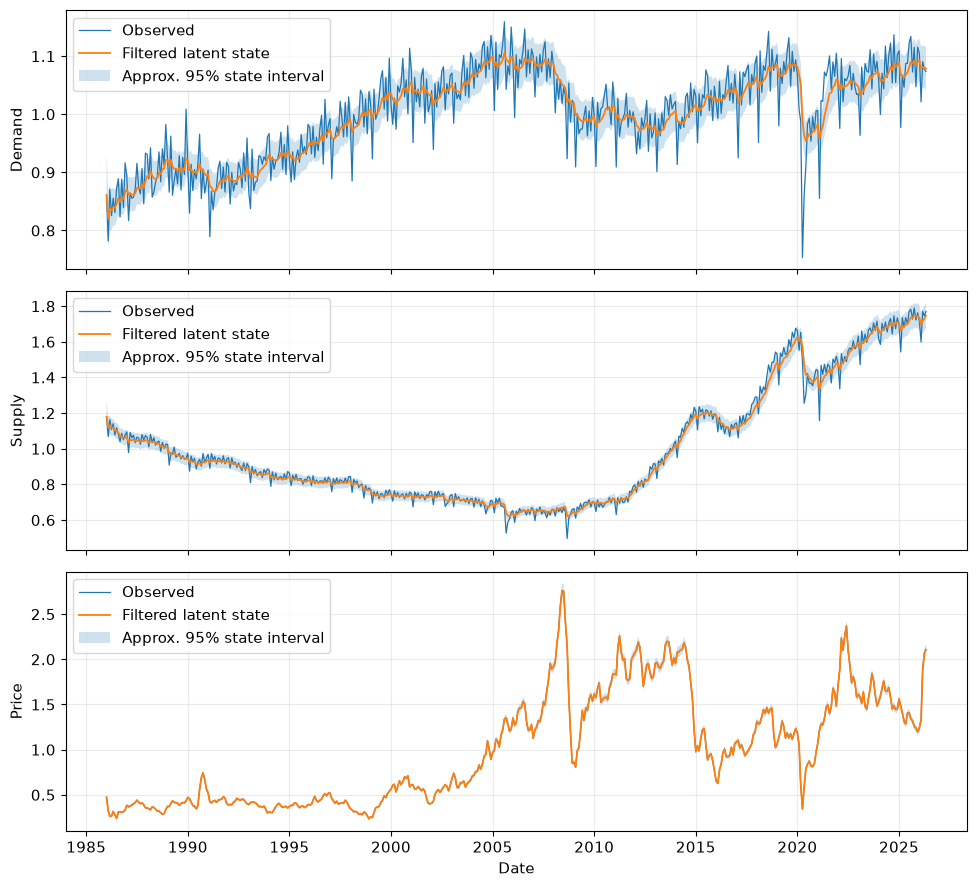

,SSE,RMSE,MAE,R2
Demand,0.566406,0.034174,0.025955,0.813162
Supply,0.522272,0.032815,0.023384,0.990092
Price,0.002476,0.002259,0.001488,0.999986


In [24]:
mf=ssm["filtered_log_mean"]; Pf=ssm["filtered_log_cov"]
sd=np.sqrt(np.maximum(np.stack([np.diag(P) for P in Pf]),0))
fmean=np.exp(mf); flo=np.exp(mf-1.96*sd); fhi=np.exp(mf+1.96*sd)

fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date,Y[:,j],lw=.9,label="Observed")
    ax.plot(df.date,fmean[:,j],lw=1.3,label="Filtered latent state")
    ax.fill_between(df.date,flo[:,j],fhi[:,j],alpha=.22,label="Approx. 95% state interval")
    ax.set_ylabel(STATE_NAMES[j]); ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"state_space_filtered_states.png",dpi=300,bbox_inches="tight")
plt.show()
display(state_metrics(Y,fmean))

### 12.3 Standardized innovation diagnostics

,State,Mean,SD,ACF1,ACF12
0,Demand,0.034078,0.983340,-0.072223,0.578476
1,Supply,0.087782,0.989919,-0.051395,0.553539
2,Price,0.026418,0.987908,0.285396,-0.027031


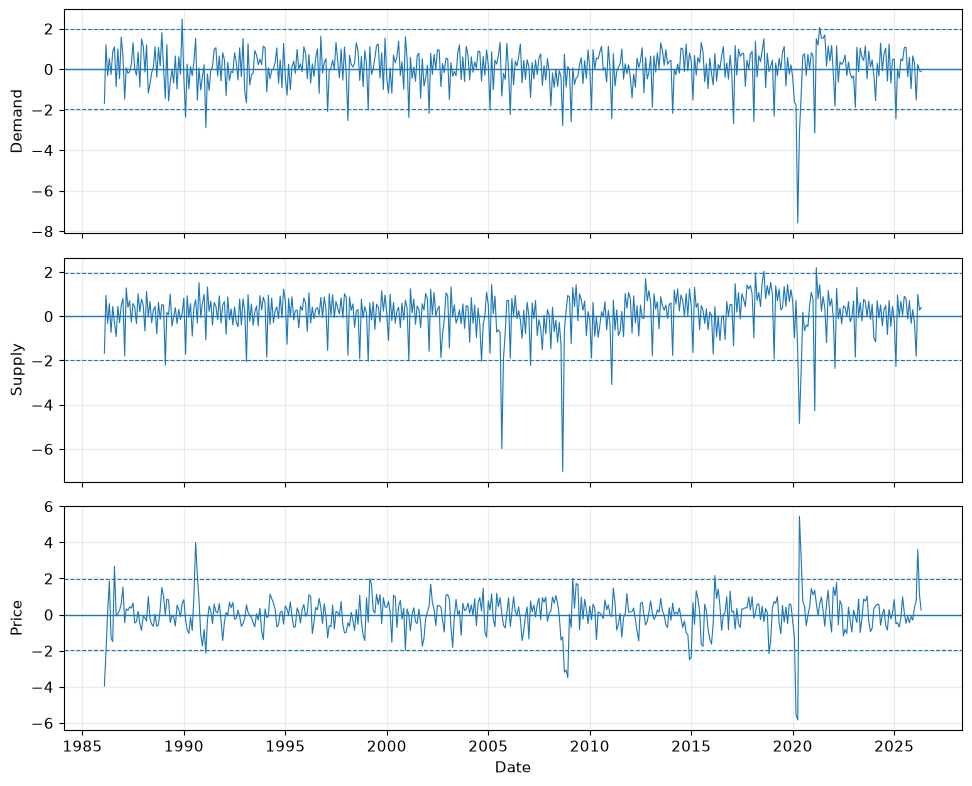

In [25]:
si=ssm["standardized_innovations"]
rows=[]
for j,name in enumerate(STATE_NAMES):
    r=si[:,j]
    rows.append([name,r.mean(),r.std(ddof=1),
                 np.corrcoef(r[:-1],r[1:])[0,1],
                 np.corrcoef(r[:-12],r[12:])[0,1]])
innov_diag=pd.DataFrame(rows,columns=["State","Mean","SD","ACF1","ACF12"])
display(innov_diag)
innov_diag.to_csv(TABDIR/"state_space_innovation_diagnostics.csv",index=False)

fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(df.date.iloc[1:],si[:,j],lw=.8)
    ax.axhline(0,lw=1); ax.axhline(1.96,ls="--",lw=.8); ax.axhline(-1.96,ls="--",lw=.8)
    ax.set_ylabel(STATE_NAMES[j])
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"state_space_standardized_innovations.png",dpi=300,bbox_inches="tight")
plt.show()

### 12.4 Model-implied stochastic trajectories

These simulations use the **estimated** process and observation variances. No arbitrary noise multiplier is introduced.

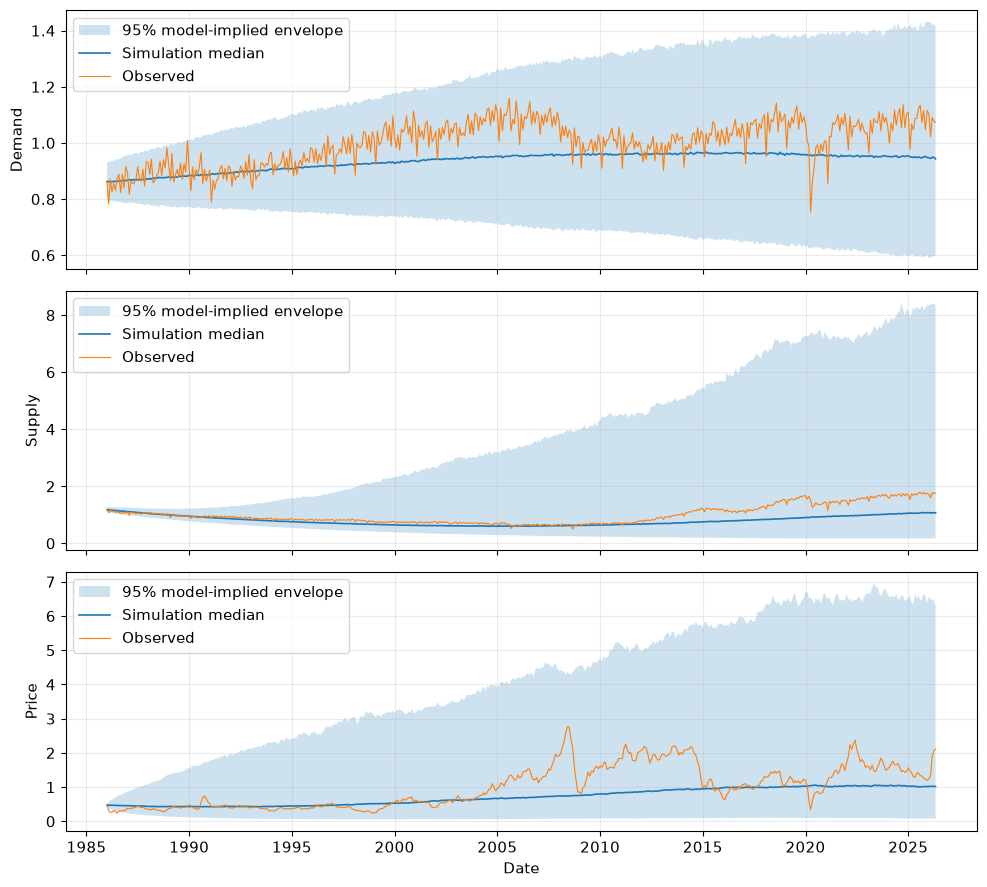

In [26]:
NSIM=300 if FAST_MODE else 3000
rg=np.random.default_rng(SEED+71)
paths=np.empty((NSIM,len(Y),3))
for r in range(NSIM):
    z=np.log(Y[0])
    paths[r,0]=np.exp(z+rg.normal(0,rsd_ssm))
    for k in range(1,len(Y)):
        z=one_month_flow_log(z,theta_ssm)+rg.normal(0,qsd_ssm)
        paths[r,k]=np.exp(z+rg.normal(0,rsd_ssm))
lo,med,hi=np.quantile(paths,[.025,.5,.975],axis=0)

fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.fill_between(df.date,lo[:,j],hi[:,j],alpha=.22,label="95% model-implied envelope")
    ax.plot(df.date,med[:,j],lw=1.2,label="Simulation median")
    ax.plot(df.date,Y[:,j],lw=.8,label="Observed")
    ax.set_ylabel(STATE_NAMES[j]); ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"estimated_state_space_simulation_envelope.png",dpi=300,bbox_inches="tight")
plt.show()

### 12.5 Genuine one-step probabilistic validation

The state-space model is re-estimated on the calibration sample only. During validation, each forecast distribution is formed **before** the new observation is assimilated. This produces genuine one-step-ahead probabilistic forecasts and allows empirical predictive-interval coverage to be measured.

,State,RMSE,MAE,R2,PI95_coverage,Mean_PI95_width
0,Demand,0.054723,0.038868,0.213547,0.907216,0.161699
1,Supply,0.075395,0.056489,0.690337,0.896907,0.262073
2,Price,0.137785,0.104175,0.856313,0.938144,0.496250


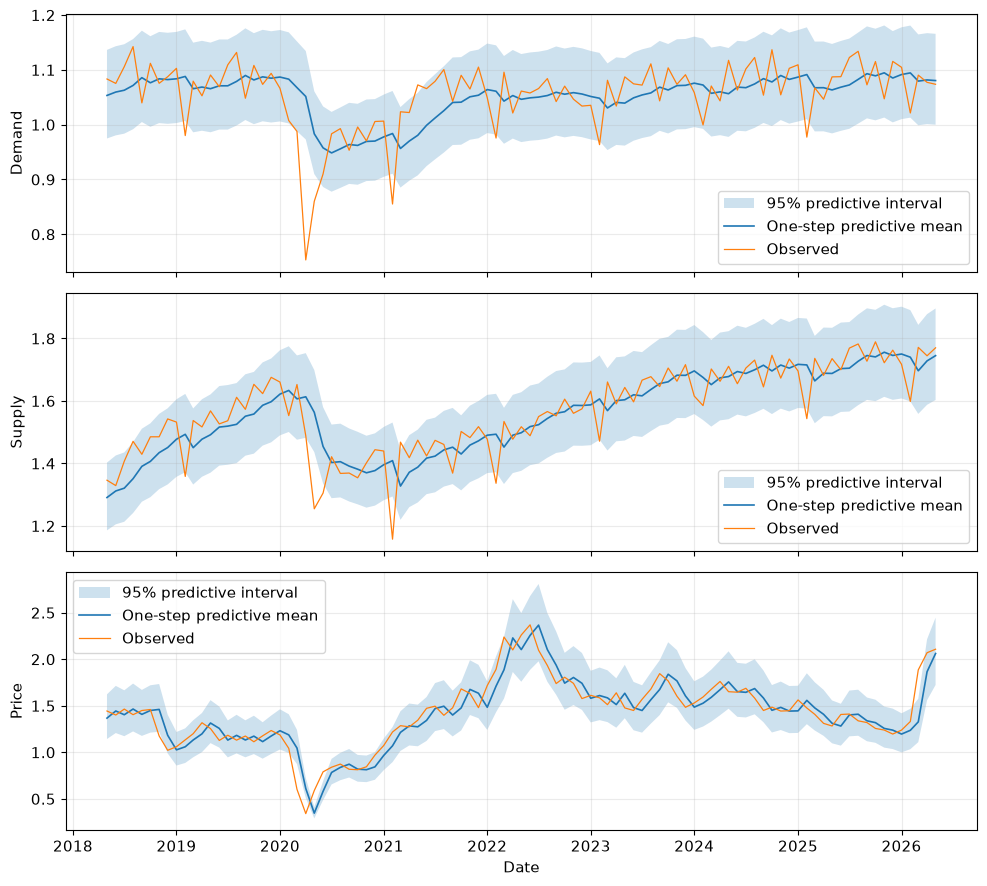

In [27]:
Ycal=Y[:n_train]
cal_opt=minimize(ekf_nll,ssm_fit.x,args=(Ycal,False),method="L-BFGS-B",
                 options={"maxiter":100 if FAST_MODE else 500,"ftol":1e-9,"maxls":30})
_,cal=ekf_nll(cal_opt.x,Ycal,True)
thc,qc,rc=unpack_ssm(cal_opt.x)
Q=np.diag(qc**2); R=np.diag(rc**2); I=np.eye(3)
m=cal["filtered_log_mean"][-1].copy(); P=cal["filtered_log_cov"][-1].copy()

PM=[]; PL=[]; PU=[]; ACT=[]
for k in range(n_train,len(Y)):
    trans=lambda zz: one_month_flow_log(zz,thc)
    a=trans(m); F=num_jac(trans,m)
    Pp=F@P@F.T+Q; Pp=(Pp+Pp.T)/2
    S=Pp+R; S=(S+S.T)/2+1e-10*I
    vv=np.diag(S)
    PM.append(np.exp(a+.5*vv))
    PL.append(np.exp(a-1.96*np.sqrt(vv)))
    PU.append(np.exp(a+1.96*np.sqrt(vv)))
    ACT.append(Y[k])

    innovation=np.log(Y[k])-a
    cf=cho_factor(S,lower=True,check_finite=False)
    K=cho_solve(cf,Pp.T,check_finite=False).T
    m=a+K@innovation
    P=(I-K)@Pp@(I-K).T+K@R@K.T; P=(P+P.T)/2

PM,PL,PU,ACT=map(np.asarray,(PM,PL,PU,ACT))
rows=[]
for j,name in enumerate(STATE_NAMES):
    mm=metrics(ACT[:,j],PM[:,j])
    coverage=np.mean((ACT[:,j]>=PL[:,j])&(ACT[:,j]<=PU[:,j]))
    width=np.mean(PU[:,j]-PL[:,j])
    rows.append([name,mm["RMSE"],mm["MAE"],mm["R2"],coverage,width])
prob=pd.DataFrame(rows,columns=["State","RMSE","MAE","R2","PI95_coverage","Mean_PI95_width"])
display(prob)
prob.to_csv(TABDIR/"state_space_probabilistic_validation.csv",index=False)

dates=df.date.iloc[n_train:]
fig,axes=plt.subplots(3,1,figsize=(10,9),sharex=True)
for j,ax in enumerate(axes):
    ax.fill_between(dates,PL[:,j],PU[:,j],alpha=.22,label="95% predictive interval")
    ax.plot(dates,PM[:,j],lw=1.2,label="One-step predictive mean")
    ax.plot(dates,ACT[:,j],lw=.9,label="Observed")
    ax.set_ylabel(STATE_NAMES[j]); ax.legend()
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(FIGDIR/"state_space_validation_predictive_intervals.png",dpi=300,bbox_inches="tight")
plt.show()